# Identification des utilisateurs de Copilote

**MOD 7.2 (Introduction à la sciences des données)**, BE séances 1, 2, 3

**Enseignants :** Julien Velcin (CM, BE), Antoine Becquet (BE)

Le projet qu'on vous demande de réaliser concerne le traitement de **traces d'utilisation** du logiciel Copilote. Ce logiciel édité par la société Infologic, concerne le secteur de l'agro-alimentaire et est utilisé par de nombreux acteurs industriels.

L'étude de ces traces est très important pour l'entreprise. Elle permet entre autre d'améliorer son offre auprès de ses clients. Le projet vous propose de travailler sur des **modèles d'analyse automatique** de ces traces.

## Résolution du problème

Nous vous proposons de suivre les étapes suivantes dans le traitement de cette problématique :

- Prendre connaissance du problème et des données à votre disposition
- Chargement des données brutes en mémoire
- Première analyse de ces données
- Construction de caractéristiques adaptées
- Statistiques simples sur les variables construites
- Développement d'une solution de classification automatique
- Evaluation de votre solution
- Discussion au sujet de vos résultats


## Prendre connaissance du problème et des données à votre disposition

Pour commencer, allez lire la description plus détaillée du problème qui vous est donnée sur la page du challenge mis en place cette année (cf. lien fourni dans l'autre notebook).

Les données sont présentées plus en détail et téléchargeables via l'onglet "data".

L'objectif consiste à comprendre à quoi correspondent chacune des lignes du tableau des données et commencer à vous poser des questions sur la manière d'utiliser ces données pour répondre au challenge. Pour le moment, vous pouvez utiliser un **simple éditeur** (comme Notepad++, Sublime Text...) pour aller voir le contenu des fichiers, les importer dans Excel (mais attention car le volume peut rendre les manipulations difficiles), ou passer déjà par Python si vous êtes suffisamment à l'aise.

## Chargement des données brutes en mémoire

La toute première étape dans le traitement des données avec Python est de les charger en mémoire pour pouvoir mieux les examiner. Plusieurs solutions s'offrent alors à vous, parmi lesquelles :

- utiliser la librairie Pandas et les méthodes qui permettent de charger directement les données dans des DataFrame comme *readcsv*,
- ouvrir le fichier texte en mode lecture (*open*) et parcourir les lignes grâce à la commande *readlines()*

Cette dernière approche semble plus robuste au regard de la régularité du fichier d'entrée. Identifiez le délimiteur qui permet de séparer les différentes actions de l'utilisateur et utilisez-le pour construire la liste des actions réalisées.

In [ ]:
import pandas as pd

def read_ds(ds_name: str):
    with open(f'data/{ds_name}.csv',encoding="utf-8") as f:
        max_actions = max(( len( str(c).split(",")) for c in f.readlines() ))
        f.seek(0)
        _names = ["util", "navigateur"] if "train" in ds_name else ["navigateur"]
        _names.extend(range(max_actions - len(_names)))
        return pd.read_csv(f, names=_names, dtype= str)

In [51]:
features_train = read_ds("train")
features_test = read_ds("test")
features_train.shape, features_test.shape

((3279, 14470), (324, 7726))

In [52]:
features_train.head()

,util,navigateur,0,1,2,3,4,5,6,7,...,14458,14459,14460,14461,14462,14463,14464,14465,14466,14467
0,nuh,Firefox,Création d'un écran(infologic.core.accueil.Acc...,Affichage d'une dialogue,Exécution d'un bouton,Fermeture d'une dialogue,Affichage d'une dialogue,Exécution d'un bouton,Fermeture d'une dialogue,Création d'un écran(infologic.core.gui.control...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,muz,Google Chrome,Création d'un écran(infologic.core.gui.control...,Création d'un écran(infologic.core.gui.control...,t5,Sélection d’un onglet(infologic.orga.modules.O...,t10,Exécution d'un bouton,t15,Sélection d’un onglet,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,zrx,Microsoft Edge,Affichage d'une dialogue(infologic.core.gui.co...,Exécution d'un bouton,Chainage,Fermeture d'une dialogue,Affichage d'une dialogue(infologic.acti.module...,Clic sur une grille d'historique de recherche,Raccourci,Fermeture d'une dialogue,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,pou,Firefox,Création d'un écran(infologic.core.gui.control...,t5,Exécution d'un bouton(MAINT),Affichage d'une dialogue,Fermeture d'une dialogue,Double-clic,Exécution d'un bouton,Lancement d'une stat(infologic.core.gui.contro...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,ald,Google Chrome,Affichage d'une dialogue(infologic.acti.module...,t5,Exécution d'un bouton,Fermeture d'une dialogue,t10,Entrée en saisie dans un formulaire,t10,Affichage d'une dialogue,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Première analyse de ces données

Les données contiennent l'utilisateur (e.g. la variable dépendante, uniquement pour l'ensemble d'apprentissage), le navigateur choisi par l'utilisateur, puis toutes les actions effectuées dans la session par l'utilisateur actuel. Un marqueur spécial « tXX » indique un intervalle de temps de 5 secondes.

In [53]:
features_train.loc[:,:20].head()

,util,navigateur,0,1,2,3,4,5,6,7,...,11,12,13,14,15,16,17,18,19,20
0,nuh,Firefox,Création d'un écran(infologic.core.accueil.Acc...,Affichage d'une dialogue,Exécution d'un bouton,Fermeture d'une dialogue,Affichage d'une dialogue,Exécution d'un bouton,Fermeture d'une dialogue,Création d'un écran(infologic.core.gui.control...,...,Fermeture d'une dialogue,Double-clic,Exécution d'un bouton,Lancement d'une stat(infologic.core.gui.contro...,Affichage d'un toast,Lancement d'une stat(infologic.core.gui.contro...,t10,Affichage d'une dialogue(MAINT),Exécution d'un bouton,Fermeture d'une dialogue
1,muz,Google Chrome,Création d'un écran(infologic.core.gui.control...,Création d'un écran(infologic.core.gui.control...,t5,Sélection d’un onglet(infologic.orga.modules.O...,t10,Exécution d'un bouton,t15,Sélection d’un onglet,...,Sélection d’un onglet(MAJ),t25,Sélection d'un écran(infologic.orga.modules.OR...,Sélection d'un écran,Exécution d'un bouton,Chainage,t30,Saisie dans un champ(MAINT)<DEF_03/24>1,Saisie dans un champ1,Saisie dans un champ1
2,zrx,Microsoft Edge,Affichage d'une dialogue(infologic.core.gui.co...,Exécution d'un bouton,Chainage,Fermeture d'une dialogue,Affichage d'une dialogue(infologic.acti.module...,Clic sur une grille d'historique de recherche,Raccourci,Fermeture d'une dialogue,...,Raccourci,Exécution d'un bouton,Affichage d'une dialogue,t10,Clic sur une grille d'historique de recherche,Raccourci,Exécution d'un bouton,Affichage d'une dialogue,Fermeture d'une dialogue,Clic sur une grille d'historique de recherche
3,pou,Firefox,Création d'un écran(infologic.core.gui.control...,t5,Exécution d'un bouton(MAINT),Affichage d'une dialogue,Fermeture d'une dialogue,Double-clic,Exécution d'un bouton,Lancement d'une stat(infologic.core.gui.contro...,...,Sélection d'un flag,Filtrage / Tri,t15,Affichage d'une dialogue,Clic sur une grille d'historique de recherche,Affichage d'une dialogue,t20,Exécution d'un bouton,Fermeture d'une dialogue,Création d'un écran(infologic.acti.modules.AT_...
4,ald,Google Chrome,Affichage d'une dialogue(infologic.acti.module...,t5,Exécution d'un bouton,Fermeture d'une dialogue,t10,Entrée en saisie dans un formulaire,t10,Affichage d'une dialogue,...,Sélection d'un écran(infologic.crm.modules.CRM...,Exécution d'un bouton,Action de table,Affichage d'un toast,Affichage d'une dialogue,Affichage d'une dialogue,Exécution d'un bouton,Fermeture d'une dialogue,Exécution d'un bouton,Entrée en saisie dans un formulaire


La première observation des données montre que nous avons un nombre considérable de colonnes (14470), mais la plupart d'entre elles semblent contenir des valeurs NaN, ce qui est logique puisque pandas étend les lignes comportant moins de colonnes afin qu'elles aient toutes le même nombre de colonnes, ajoutant ainsi des valeurs NaN aux champs manquants. Quelques utilisateurs ont gardé la même session pendant une très longue durée, alors que la plupart ont des sessions plus courtes ou de durée moyenne. Ainsi, les quelques sessions longues ont entraîné l'extension de toutes les autres à leur durée. C'est de là que proviennent toutes ces valeurs NaN.

In [54]:
# TODO: Inspecter les valeurs distinctes des navigateurs

In [55]:
print(features_train["navigateur"].value_counts())
print(features_test["navigateur"].value_counts())

navigateur
Firefox           1466
Google Chrome     1339
Microsoft Edge     451
Opera               23
Name: count, dtype: int64
navigateur
Firefox           147
Google Chrome     133
Microsoft Edge     42
Opera               2
Name: count, dtype: int64


Quelques fonctions "utilitaires" qui pourraient vous être utiles (ou pas) :

In [56]:
import warnings
import math
from IPython.display import display, Markdown

# décorateurs utilitaires pour supprimer les avertissements de la sortie et imprimer un cadre de données dans un tableau Markdown.
def ignore_warnings(f):
    def _f(*args, **kwargs):
        warnings.filterwarnings('ignore')
        v = f(*args, **kwargs)
        warnings.filterwarnings('default')
        return v
    return _f

# affiche un DataFrame Pandas sous forme de tableau Markdown dans un notebook Jupyter.
def markdown_table(headNtail=False, use_index=True, title=None, precision=2):
    def _get_value(val): return str(round(val, precision) if isinstance(val, float) else val)
    def _format_row(row): 
        row_str = ""
        if use_index: row_str += f"|{str(row.name)}"
        for value in row.values: row_str += f"| {_get_value(value)}"
        return row_str + "|"
    def _get_str(df):
        return "\n".join(df.apply(_format_row, axis=1))
    def _deco(f):
        def _f(*args, **kwargs):
            df = f(*args, **kwargs)
            _str = f"#### {title}\n" if title else ""
            header = ([str(df.index.name)] if use_index else []) + df.columns.astype(str).to_list() 
            _str += f"|{'|'.join(header)}|" + f"\n|{'--|'*len(header)}\n" if header else None
            if headNtail:
                _str += _get_str(df.head())
                _str += "\n|...|...|\n"
                _str += _get_str(df.tail())
            else:
                _str += _get_str(df)
            display(Markdown(_str))
        return _f
    return _deco

# fonction utilitaire permettant d'obtenir une grille graphique à partir d'un nombre arbitraire de lignes/colonnes ou de données.
def get_grid(n, n_row=None, n_col=None, titles=None, figsize=(10, 8), wspace=.5, hspace=.5, **kwargs):
    if n_row: n_col= n_col or math.floor(n/n_row)
    elif n_col: n_row= n_row or math.ceil(n/n_col)
    else:
        n_row = math.ceil(math.sqrt(n))
        n_col = math.floor(n/n_row)
    fig, axs = plt.subplots(n_row, n_col, figsize=figsize, **kwargs)
    plt.subplots_adjust(hspace=hspace, wspace=wspace)
    if titles is not None:
        for ax, title in zip(axs.flat, titles): ax.set_title(title)
    return fig, axs

Maintenant que nous avons un premier aperçu de nos données, approfondissons un peu et examinons quelques statistiques à leur sujet.

In [57]:
@markdown_table(title="Navigateur par utilisateur", headNtail=True)
def browsers_per_player(df):
    # Afficher ici pour chaque utilisateur (en ligne) le nombre de fois qu'il a utilisé chaque navigateur (en colonne)
    return pd.crosstab(df["util"], df["navigateur"])
browsers_per_player(features_train)
# TODO: inspecter d'autre statistiques du jeu de données (la variable dépendante Y sera inspecté dans la prochaine cellule)

#### Navigateur par utilisateur
|util|Firefox|Google Chrome|Microsoft Edge|Opera|
|--|--|--|--|--|
|aho| 0| 10| 0| 0|
|ajo| 13| 0| 0| 0|
|akx| 0| 14| 0| 0|
|ald| 0| 15| 0| 0|
|ats| 12| 0| 0| 0|
|...|...|
|zqs| 0| 0| 16| 0|
|zro| 13| 0| 0| 0|
|zrx| 0| 0| 12| 0|
|zus| 13| 0| 0| 0|
|zyk| 0| 21| 0| 0|

Il y a 4 navigateurs ; Firefox (45 %) et Chrome (41 %) dominent, Opera est marginal. La répartition est identique entre train et test. Chaque utilisateur n'utilise qu'un seul navigateur (114 sur Firefox, 93 sur Chrome, 39 sur Edge, 1 sur Opera) : le navigateur est donc une caractéristique très discriminante, qui réduit fortement le nombre de candidats, mais qui ne suffit pas seule à identifier l'utilisateur.

// Votre analyse ici

In [58]:
@markdown_table(headNtail=True, title="Stats: Y distribution")
def get_Y_stats(df):
    # Inspecter la distribution de la variable dépendante ici (Y)
    counts = df["util"].value_counts()
    return pd.DataFrame({"nb_sessions": counts,
                         "proportion_%": 100 * counts / counts.sum()})

get_Y_stats(features_train)

y_counts = features_train["util"].value_counts()
print(f"{y_counts.size} utilisateurs distincts")
print(y_counts.describe())

#### Stats: Y distribution
|util|nb_sessions|proportion_%|
|--|--|--|
|skm| 75.0| 2.29|
|slq| 71.0| 2.17|
|cjr| 46.0| 1.4|
|flj| 42.0| 1.28|
|hjs| 37.0| 1.13|
|...|...|
|zll| 4.0| 0.12|
|itt| 4.0| 0.12|
|lra| 4.0| 0.12|
|bez| 4.0| 0.12|
|crn| 4.0| 0.12|

247 utilisateurs distincts
count    247.000000
mean      13.275304
std        8.862380
min        4.000000
25%        7.000000
50%       12.000000
75%       16.000000
max       75.000000
Name: count, dtype: float64


Il y a 247 utilisateurs (classes) pour 3279 sessions, soit environ 13 sessions par utilisateur en moyenne (médiane 12). Les classes sont déséquilibrées : de 4 sessions pour les plus rares à 75 pour le plus fréquent (skm). C'est un problème multi-classes difficile, avec peu d'exemples par classe.

## Construction de caractéristiques

### Traitements préliminaires

En fonction du modèle choisi, différentes étapes de pré-traitement peuvent être nécessaire. Voir https://scikit-learn.org/stable/supervised_learning.html pour des exemples de modèles dans le cas supervisé (notre cas). Quelques exemples : 
- SVMs
- Régression logistiques
- Arbres de décision
- Modèle ensembliste (Random Forest, XGBoost, etc.)
- Réseaux de neurones 

Il faut commencer par se demander s'il y a des valeurs aberrantes (*outliers*) et, le cas échéant, appliquer le traitement approprié (pour le moment vous pouvez à priori les supprimer).

count     3279.000000
mean       850.238792
std       1212.323701
min          2.000000
25%        192.000000
50%        423.000000
75%       1019.000000
max      14468.000000
dtype: float64
Bornes : entre 16 et 12459 éléments
5 sessions aberrantes sur 3279
util
fvc    1
zus    1
wvy    1
fou    1
fxg    1
Name: count, dtype: int64


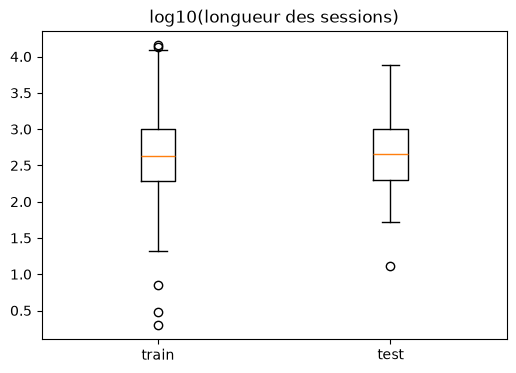

In [59]:
# TODO: inspecter s'il y a des valeurs aberrantes, et les enlever le cas échéant
import numpy as np
import matplotlib.pyplot as plt

# Longueur de chaque session = nombre de cases non vides (actions + marqueurs tXX)
longueur_train = features_train.iloc[:, 2:].notna().sum(axis=1)
longueur_test = features_test.iloc[:, 1:].notna().sum(axis=1)
print(longueur_train.describe())

# Règle de l'IQR, appliquée sur le log de la longueur
log_long = np.log10(longueur_train)
q1, q3 = log_long.quantile([0.25, 0.75])
iqr = q3 - q1
borne_basse, borne_haute = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = (log_long < borne_basse) | (log_long > borne_haute)

print(f"Bornes : entre {10**borne_basse:.0f} et {10**borne_haute:.0f} éléments")
print(f"{outliers.sum()} sessions aberrantes sur {len(outliers)}")
print(features_train.loc[outliers, "util"].value_counts())

fig, ax = plt.subplots(figsize=(6, 4))
ax.boxplot([np.log10(longueur_train), np.log10(longueur_test)])
ax.set_xticks([1, 2], ["train", "test"])
ax.set_title("log10(longueur des sessions)")
plt.show()


### Variable de classe
Notre variable dépendante est une chaîne de caractères (str). Nous pouvons la convertir en codes catégoriels (numériques) à l'aide de la fonction pd.Categorical.

In [60]:
features_train["util"] = pd.Categorical(features_train["util"])

pd.Categorical ne modifie pas directement l'ID utilisateur en un nombre, mais lui ajoute un attribut cat.codes. Nous pouvons créer une petite fonction pour convertir la variable de classe d'une chaîne de caractères en son ID de catégorie :

In [61]:
def to_categories(df, col="util"):
    df[[col]] = df[[col]].apply(lambda x: x.cat.codes)

### Obtention des caractéristiques...

Nous allons maintenant créer des caractéristiques à partir de l'ensemble de données. Pour cela, il va falloir comprendre leur format, les parser et voir comment les agréger. On peut commencer par inspecter toutes les actions différentes, indépendemment des informations sur l'écran ou la fiche travaillée.

In [62]:
def filter_action(value: str):
    for delim in [ "(", "<", "$", "1"]:
        if delim in value and (low_ind := value.index(delim)):
            value = value[:low_ind]
    return value

uniques = features_train.iloc[:,2:].stack().dropna().unique()
filtered_uniques = list(set([filter_action(un) for un in uniques if not un.startswith("t")]))
len(filtered_uniques), filtered_uniques

(35,
 ["Affichage d'une erreur",
  "Lancement d'une action infocentre",
  "Désélection d'un flag",
  "Fermeture d'un panel",
  'Saisie dans un champ',
  "Démarrage serveur d'application Tomcat",
  "Affichage d'une dialogue",
  "Désélection d'un élément",
  'Double-clic',
  "Lancement d'un tableau de bord",
  "Affichage d'une arborescence",
  'Clic sur une checkbox',
  'Filtrage / Tri',
  'Action de table',
  "Dissimulation d'une arborescence",
  'Erreur système grave',
  "Création d'un écran",
  "Raccourci dans l'édition de table",
  "Lancement d'une action générique",
  'Sélection d’un onglet',
  'Fermeture de session',
  "Clic sur une grille d'historique de recherche",
  "Lancement d'une stat",
  'Entrée en saisie dans un formulaire',
  "Sélection d'un écran",
  "Affichage d'un toast",
  'Raccourci',
  'Clic long',
  "Exécution d'un bouton",
  "Sélection d'un flag",
  "Ouverture d'un panel",
  "Sélection d'un élément",
  'Retour sur un écran',
  "Fermeture d'une dialogue",
  'Chainag

In [63]:
#TODO Définir des features sur les données brutes et les placer dans un nouveau dataframe

import re
from collections import Counter

# 1) Transformer chaque ligne du tableau en liste d'actions (sans les NaN)
def get_sessions(df):
    debut = 2 if "util" in df.columns else 1      # le test n'a pas de colonne util
    return [[v for v in ligne if isinstance(v, str)] for ligne in df.iloc[:, debut:].to_numpy()]

sessions_train = get_sessions(features_train)
sessions_test = get_sessions(features_test)

# 2) Reconnaître un marqueur de temps : "t" suivi uniquement de chiffres (t5, t10, t125...)
def est_temps(a):
    return re.fullmatch(r"t\d+", a) is not None

# 3) Calculer les caractéristiques de chaque session
def build_features(sessions):
    lignes = []
    for s in sessions:
        actions = [a for a in s if not est_temps(a)]
        temps = [int(a[1:]) for a in s if est_temps(a)]
        n = max(len(actions), 1)                   # évite une division par 0
        duree = max(temps, default=0)
        f = {"n_actions": len(actions),
             "duree": duree,
             "actions_means": len(actions) / (duree / 5 + 1)}
        compte = Counter(filter_action(a) for a in actions)
        for type_action in filtered_uniques:
            f["freq_" + type_action] = compte.get(type_action, 0) / n
        lignes.append(f)
    return pd.DataFrame(lignes)

X_train = build_features(sessions_train)
X_test = build_features(sessions_test)
X_train.shape, X_test.shape



KeyboardInterrupt: 

Ensuite, on peut employer des fonctions plus complexes pour extraire l'écran le plus utilisé, la configuration d'écran la plus utilisé et la chaîne (catégorie) de la fiche la plus utilisé. Pour vous aider, voici les expressions régulières (*regex*) qui permettent d'extraire de telles informations. N'hésitez pas à extraire d'autres informations si cela vous parait pertinent.

In [ ]:
import re
from collections import Counter

pattern_ecran = re.compile(r"\((.*?)\)")
pattern_conf_ecran = re.compile(r"<(.*?)>")
pattern_chaine = re.compile(r"\$(.*?)\$")

def le_plus_frequent(valeurs):
    # renvoie la valeur la plus fréquente de la liste, ou "aucun" si la liste est vide
    return Counter(valeurs).most_common(1)[0][0] if valeurs else "aucun"

def regex_features(sessions):
    lignes = []
    for s in sessions:
        # on applique les regex action par action
        ecrans = [m for a in s for m in pattern_ecran.findall(a)]
        confs = [m for a in s for m in pattern_conf_ecran.findall(a)]
        chaines = [m for a in s for m in pattern_chaine.findall(a)]
        lignes.append({
            "ecran_top": le_plus_frequent(ecrans),
            "conf_top": le_plus_frequent(confs),
            "chaine_top": le_plus_frequent(chaines),
            "n_ecrans_distincts": len(set(ecrans)),
            "n_confs_distinctes": len(set(confs)),
            "n_chaines_distinctes": len(set(chaines)),
        })
    return pd.DataFrame(lignes)

X_regex_train = regex_features(sessions_train)
X_regex_test = regex_features(sessions_test)
X_regex_train.head()



,ecran_top,conf_top,chaine_top,n_ecrans_distincts,n_confs_distinctes,n_chaines_distinctes
0,MAINT,DEF_03/24,JCP,7,3,2
1,infologic.orga.modules.OR_FICHIERTRAVAIL.Insta...,TELEM_MINIMAL,DB,5,2,2
2,DEMTEST,DEF_07/23,MES,17,7,2
3,MAINT,DEF_03/24,JCP,10,4,1
4,MAINT,INSTALLATEUR,GP,8,4,2


### Traitement des chaînes de caractère
La colonne navigateur ne peut prendre que quatre valeurs ; pour la convertir en nombre, on a deux choix : 
- la convertir en variable catégorielle comme nous l'avons fait avec notre variable dépendante
- la convertir en One-Hot Encoding (OHE), un pour chaque navigateur. Pandas propose également une fonction pour cela : get_dummies

En fonction du modèle, l'un ou l'autre peut être plus pertinent (par exemple, pour un arbre de décision ?).

In [ ]:
#TODO : traiter les chaînes de caractères

# 1) Navigateur -> One-Hot Encoding (4 colonnes 0/1)
nav_train = pd.get_dummies(features_train["navigateur"], prefix="nav", dtype=int)
nav_test = pd.get_dummies(features_test["navigateur"], prefix="nav", dtype=int)
nav_test = nav_test.reindex(columns=nav_train.columns, fill_value=0)

# 2) Écran / configuration / chaîne les plus utilisés -> codes catégoriels
#    Les catégories sont apprises sur le TRAIN ; une valeur inconnue dans le test reçoit le code -1
cat_train, cat_test = pd.DataFrame(), pd.DataFrame()
for col in ["ecran_top", "conf_top", "chaine_top"]:
    categories = pd.Categorical(X_regex_train[col]).categories
    cat_train[col] = pd.Categorical(X_regex_train[col], categories=categories).codes
    cat_test[col] = pd.Categorical(X_regex_test[col], categories=categories).codes

# 3) On assemble toutes les caractéristiques dans un seul tableau
colonnes_num = ["n_ecrans_distincts", "n_confs_distinctes", "n_chaines_distinctes"]
X_hand_train = pd.concat([nav_train, X_train, X_regex_train[colonnes_num], cat_train], axis=1)
X_hand_test = pd.concat([nav_test, X_test, X_regex_test[colonnes_num], cat_test], axis=1)

# 4) La variable à prédire en nombres (sans modifier features_train, cf. cellule de soumission)
y = features_train["util"].cat.codes.to_numpy()

print(X_hand_train.shape, X_hand_test.shape)
print("Valeurs du test inconnues du train :", (cat_test == -1).sum().to_dict())
X_hand_train.head()


(3279, 48) (324, 48)
Valeurs du test inconnues du train : {'ecran_top': 3, 'conf_top': 2, 'chaine_top': 2}


C:\Users\sarah\AppData\Local\Temp\ipykernel_11920\2692572800.py:14: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  cat_test[col] = pd.Categorical(X_regex_test[col], categories=categories).codes


,nav_Firefox,nav_Google Chrome,nav_Microsoft Edge,nav_Opera,n_actions,duree,actions_means,freq_Affichage d'une erreur,freq_Lancement d'une action infocentre,freq_Désélection d'un flag,...,freq_Sélection d'un élément,freq_Retour sur un écran,freq_Fermeture d'une dialogue,freq_Chainage,n_ecrans_distincts,n_confs_distinctes,n_chaines_distinctes,ecran_top,conf_top,chaine_top
0,1,0,0,0,2514,2905,4.319588,0.002387,0.0,0.0,...,0.000000,0.000796,0.146778,0.003182,7,3,2,13,48,23
1,0,1,0,0,90,230,1.914894,0.000000,0.0,0.0,...,0.000000,0.000000,0.022222,0.033333,5,2,2,104,96,5
2,0,0,1,0,608,750,4.026490,0.000000,0.0,0.0,...,0.016447,0.006579,0.062500,0.052632,17,7,2,3,49,28
3,1,0,0,0,886,1445,3.055172,0.001129,0.0,0.0,...,0.000000,0.019187,0.047404,0.025959,10,4,1,13,48,23
4,0,1,0,0,173,275,3.089286,0.000000,0.0,0.0,...,0.000000,0.000000,0.057803,0.023121,8,4,2,13,67,20


## Statistiques simples sur les variables

### Inspection des caractéristiques

Commencez par inspecter les caractéristiques que vous avez construites, et afficher des graphiques en les interprétant. Vous pouvez utiliser la librairie Matplotlib à cette fin.

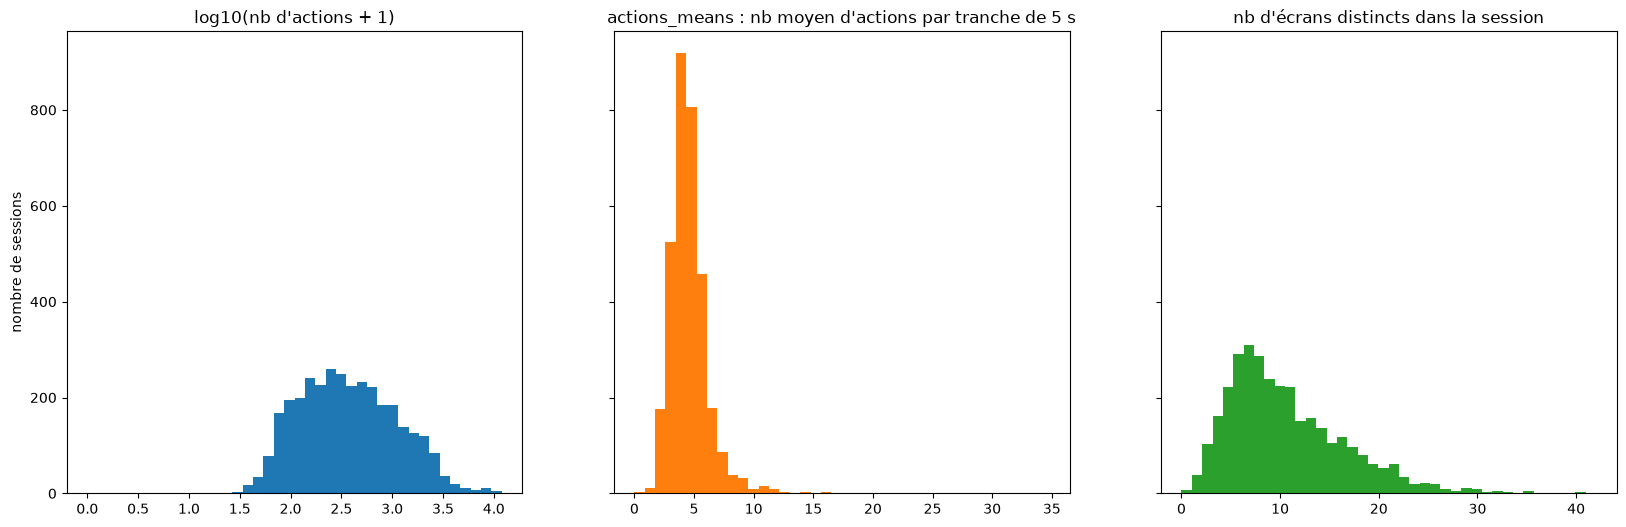

In [ ]:
fig, (ax1, ax2, ax3) = plt.subplots(ncols=3, sharey=True, figsize=(20,6))
# TODO: afficher des graphiques de trois features différentes sur les trois axes donnés

ax1.hist(np.log10(X_hand_train["n_actions"] + 1), bins=40, color="tab:blue")
ax1.set_title("log10(nb d'actions + 1)")
ax1.set_ylabel("nombre de sessions")

ax2.hist(X_hand_train["actions_means"], bins=40, color="tab:orange")
ax2.set_title("actions_means : nb moyen d'actions par tranche de 5 s")

ax3.hist(X_hand_train["n_ecrans_distincts"], bins=40, color="tab:green")
ax3.set_title("nb d'écrans distincts dans la session")

plt.show()

// Votre analyse ici

Nombre d'actions : en échelle log, la distribution est proche d'une cloche (loi log-normale), centrée autour de 250–400 actions, avec des sessions allant de ~30 à ~10 000 actions. Le passage au log est nécessaire pour la lisibilité et pour les modèles sensibles à l'échelle.

actions_means : distribution très concentrée autour de 4–5 actions par tranche de 5 s (environ une action par seconde), avec une petite traîne vers des rythmes très élevés. La plupart des utilisateurs ont un rythme similaire : cette variable sera peu discriminante, sauf pour les profils extrêmes.

Nombre d'écrans distincts : distribution asymétrique, la plupart des sessions n'utilisent que 5 à 10 écrans. Chaque utilisateur travaille dans un périmètre fonctionnel restreint : l'identité des écrans utilisés devrait être un indice fort pour reconnaître l'utilisateur.

### Inspection de la corrélation d'une caractéristique pour une classe particulière
Comme il peut être difficile d'inspecter les données lorsque nous avons un tel nombre de classes possibles, nous pouvons commencer par tracer des graphiques de corrélation pour une ou quelques cibles particulières, choisies arbitrairement.


In [ ]:
def plot_categories(categories, type_="box", feature="actions_means"):
    fig, axs = get_grid(len(categories), n_row=1, figsize=(16, 4))
    # TODO : afficher les graphiques des catégories passées en paramètre
    valeurs = X_hand_train[feature]
    noms = features_train["util"].cat.categories
    for ax, cat in zip(np.ravel(axs), categories):
        donnees = [valeurs[y == cat], valeurs[y != cat]]   # cet utilisateur / tous les autres
        if type_ == "violin":
            ax.violinplot(donnees, showmedians=True)
        else:
            ax.boxplot(donnees)
        ax.set_xticks([1, 2], [f"{noms[cat]} (n={len(donnees[0])})", "autres"])
        ax.set_title(f"classe {cat} : {feature}")
    plt.show()

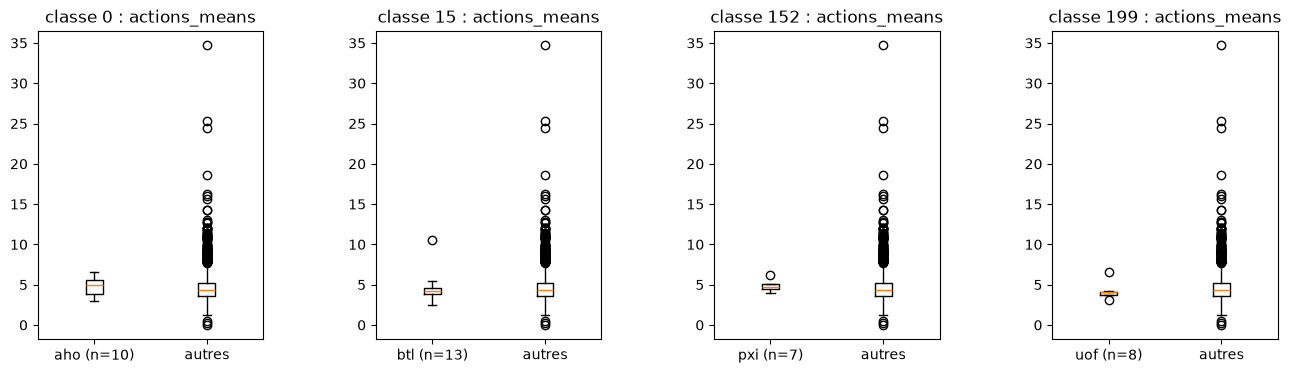

In [ ]:
categories = [0, 15, 152, 199]
plot_categories(categories)

Pour les quatre utilisateurs étudiés (aho, btl, pxi, uof), la médiane de actions_means (≈ 4–5 actions par tranche de 5 s) est très proche de celle de l'ensemble des autres utilisateurs, et leurs boîtes sont incluses dans celle des autres : le rythme seul ne permet pas de les distinguer. On remarque toutefois que leurs boîtes sont plus étroites : chaque utilisateur est régulier d'une session à l'autre, alors que la population globale est plus variée. Avec 247 classes, aucune caractéristique isolée ne suffit : il faut combiner de nombreuses caractéristiques (navigateur, types d'actions, écrans utilisés…) pour identifier un utilisateur.

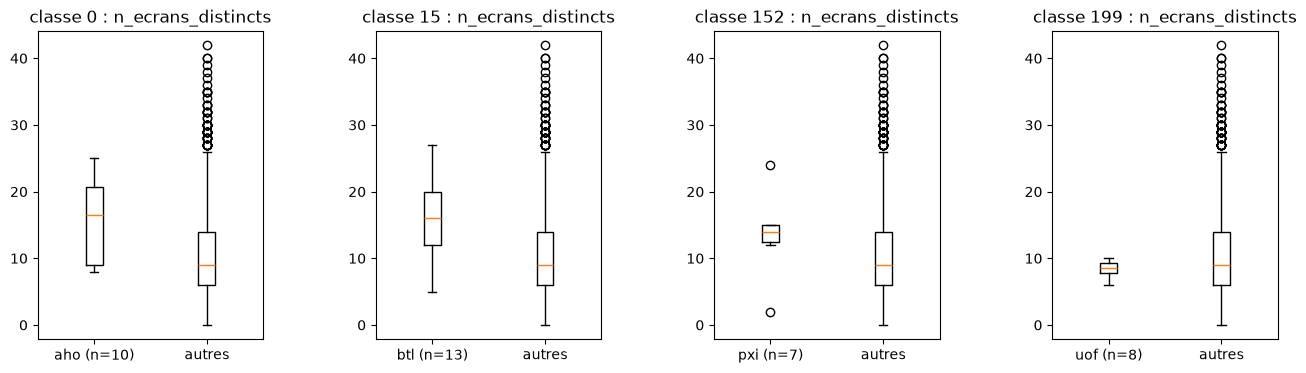

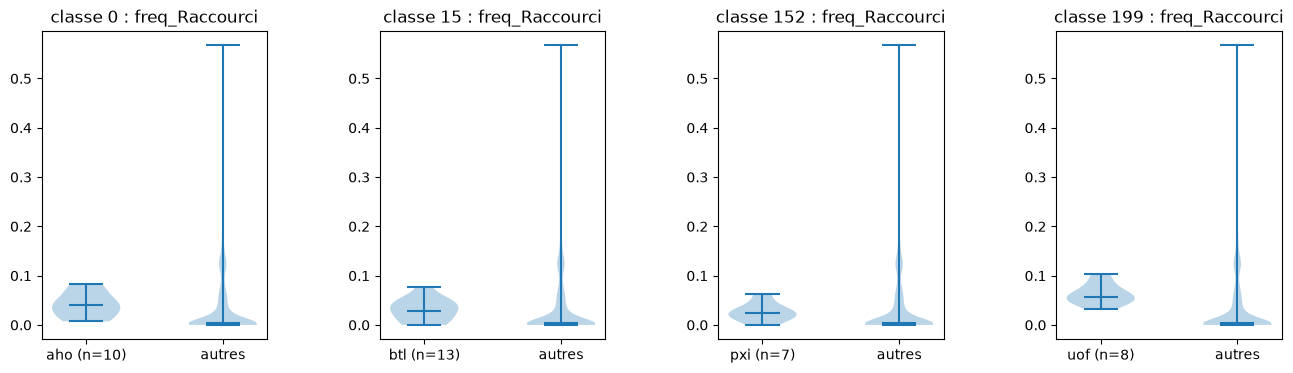

In [ ]:
plot_categories(categories, feature="n_ecrans_distincts")
plot_categories(categories, feature="freq_Raccourci", type_="violin")


Un boxplot est très utile pour estimer la distribution d'une caractéristique au sein d'une catégorie (cf. cours), mais d'autres visualisations peuvent servir comme les violin plots, cf. : https://www.data-to-viz.com



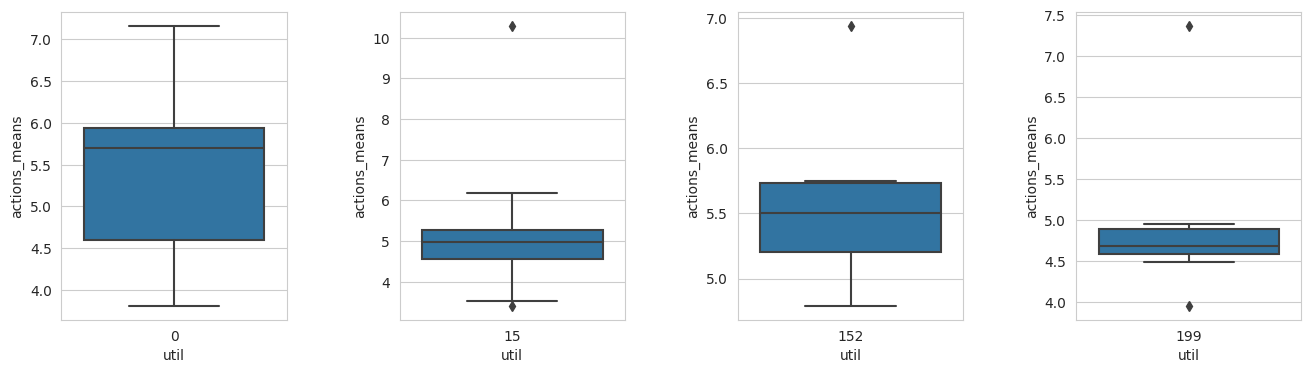

 D'autres caractéristiques sont plus discriminantes que le rythme. Le nombre d'écrans distincts place aho et btl (médiane ≈ 16) nettement au-dessus de la population (médiane ≈ 9), et pxi et uof se distinguent par une très faible variabilité. La fréquence des raccourcis montre que la majorité des sessions n'en utilise presque jamais, alors que nos quatre utilisateurs en utilisent systématiquement (2 à 6 %). uof, en particulier, n'a aucune session à moins de ~3,5 %. Chaque caractéristique prise seule chevauche encore la population, mais leur combinaison (avec le navigateur) permet de restreindre fortement les candidats

## Développement d'une solution de classification automatique

Une fois que vous avez exploré les données et mieux compris comment résoudre la tâche qui vous est confiée, c'est le moment de commencer à développer votre solution de classification automatique supervisée.

La première opération consiste à séparer votre jeu de données en deux sous-ensembles : un jeu d'entraînement (**training set**) et un jeu de validation (**validation set**). Le jeu de validation vous aidera dans la sélection du meilleur modèle. Suivant les algorithmes employés, et leur coût computationnel, vous pourriez aussi avoir recours à la validation croisée à K-folds (*K-fold cross validation*).

Il s'agit ensuite de tester plusieurs algorithmes classiques et de faire varier ses hyper-paramètres, tel que :

- Régression logistique
- Machines à vecteurs supports (SVM) : différents types de noyau (linéaire, polynomial à différents degrés)
- Arbres de décisions simples
- Ensembles d'arbres (Random Forest, XGBoost) : nombre d'arbres
- Réseaux de neurones artificiels (simple MLP) : nombre de couches, nombre de neurones par couche

Vous pouvez également tester les méthodes de régularisation afin d'obtenir des modèles parcimonieux.

Pour cela, vous privilégierez l'usage de la librairie *scikit-learn*.

In [ ]:
# séparer entraînement et validation
from sklearn.model_selection import train_test_split

X_tr, X_val, y_tr, y_val = train_test_split(X_hand_train, y, test_size=0.2,
                                            stratify=y, random_state=42)
print(X_tr.shape, X_val.shape)
print("Utilisateurs présents dans la validation :", len(np.unique(y_val)))


(2623, 48) (656, 48)
Utilisateurs présents dans la validation : 247


In [ ]:
# entraîner et comparer plusieurs modèles

import time
from sklearn.metrics import accuracy_score, f1_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

modeles = {
    "Régression logistique": make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
    "Arbre de décision": DecisionTreeClassifier(random_state=0),
    "Random Forest (100 arbres)": RandomForestClassifier(n_estimators=100, random_state=0, n_jobs=-1),
    "Random Forest (500 arbres)": RandomForestClassifier(n_estimators=500, random_state=0, n_jobs=-1),
}

resultats = []
for nom, modele in modeles.items():
    t0 = time.time()
    modele.fit(X_tr, y_tr)              # apprentissage sur 80 % des sessions
    pred = modele.predict(X_val)        # prédiction sur les 20 % jamais vues
    resultats.append({"modèle": nom,
                      "accuracy": accuracy_score(y_val, pred),
                      "f1_macro": f1_score(y_val, pred, average="macro"),
                      "temps (s)": time.time() - t0})

pd.DataFrame(resultats).set_index("modèle").round(3)


,accuracy,f1_macro,temps (s)
modèle,,,
Régression logistique,0.817,0.803,2.135
Arbre de décision,0.671,0.617,0.667
Random Forest (100 arbres),0.854,0.819,2.020
Random Forest (500 arbres),0.861,0.831,7.027


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

def session_tokens(session, navigateur):
    tokens = ["NAV=" + navigateur]
    precedente = None
    for a in session:
        if est_temps(a):
            continue                                   # on ignore les marqueurs t5, t10...
        act = filter_action(a)
        tokens.append("A=" + act)                      # type d'action
        for m in pattern_ecran.findall(a):
            tokens += ["E=" + m, "AE=" + act + "|" + m]   # écran, et action sur cet écran
        tokens += ["C=" + m for m in pattern_conf_ecran.findall(a)]   # configurations
        tokens += ["H=" + m for m in pattern_chaine.findall(a)]       # chaînes
        if precedente is not None:
            tokens.append("B=" + precedente + ">" + act)  # enchaînement de 2 actions
        precedente = act
    return tokens

docs_train = [session_tokens(s, n) for s, n in zip(sessions_train, features_train["navigateur"])]
docs_test = [session_tokens(s, n) for s, n in zip(sessions_test, features_test["navigateur"])]

tfidf = TfidfVectorizer(analyzer=lambda tokens: tokens, sublinear_tf=True)
X_tfidf_train = tfidf.fit_transform(docs_train)   # apprend le vocabulaire et les IDF sur le TRAIN
X_tfidf_test = tfidf.transform(docs_test)         # applique le même vocabulaire au test

print(X_tfidf_train.shape, X_tfidf_test.shape)
docs_train[1][:12]


(3279, 3493) (324, 3493)


['NAV=Google Chrome',
 "A=Création d'un écran",
 'E=infologic.core.gui.controllers.BlankController',
 "AE=Création d'un écran|infologic.core.gui.controllers.BlankController",
 "A=Création d'un écran",
 'E=infologic.core.gui.controllers.nested.InputFormNestedWindow',
 "AE=Création d'un écran|infologic.core.gui.controllers.nested.InputFormNestedWindow",
 "B=Création d'un écran>Création d'un écran",
 'A=Sélection d’un onglet',
 'E=infologic.orga.modules.OR_FICHIERTRAVAIL.InstanceForm',
 'AE=Sélection d’un onglet|infologic.orga.modules.OR_FICHIERTRAVAIL.InstanceForm',
 'C=TELEM_MINIMAL']

(3279, 3493) (324, 3493) : chaque session est maintenant décrite par 3 493 caractéristiques, une par « mot » différent, avec les mêmes colonnes pour le train et le test.

Les 12 mots affichés montrent comment la session n°1 a été traduite : navigateur Chrome, création de deux écrans, sélection d'un onglet sur l'écran OR_FICHIERTRAVAIL, configuration TELEM_MINIMAL… On lit littéralement ce que l'utilisateur a fait.

In [ ]:
from sklearn.svm import LinearSVC

# Même découpage que précédemment (même y, même random_state) pour comparer équitablement
idx_tr, idx_val = train_test_split(np.arange(len(y)), test_size=0.2, stratify=y, random_state=42)

modeles_tfidf = {
    "Régression logistique (C=20)": LogisticRegression(C=20, max_iter=3000),
    "SVM linéaire (C=1)": LinearSVC(C=1),
    "Random Forest (500 arbres)": RandomForestClassifier(n_estimators=500, random_state=0, n_jobs=-1),
}

resultats_tfidf = []
for nom, modele in modeles_tfidf.items():
    t0 = time.time()
    modele.fit(X_tfidf_train[idx_tr], y[idx_tr])
    pred = modele.predict(X_tfidf_train[idx_val])
    resultats_tfidf.append({"modèle": nom,
                            "accuracy": accuracy_score(y[idx_val], pred),
                            "f1_macro": f1_score(y[idx_val], pred, average="macro"),
                            "temps (s)": time.time() - t0})

pd.DataFrame(resultats_tfidf).set_index("modèle").round(3)

,accuracy,f1_macro,temps (s)
modèle,,,
Régression logistique (C=20),0.944,0.924,17.109
SVM linéaire (C=1),0.948,0.927,3.615
Random Forest (500 arbres),0.928,0.890,15.768


1. Un énorme bond de performance. On passe de 86 % à 95 %, soit environ trois fois moins d'erreurs (de 14 % à 5 %). Ce n'est pas le modèle qui a changé, c'est la représentation des données. Garder tous les écrans, configurations et enchaînements, au lieu d'un résumé, conserve « l'empreinte » complète de chaque utilisateur. C'est une leçon classique en machine learning : de bonnes caractéristiques comptent souvent plus que le choix du modèle.

2. Les modèles linéaires passent devant la Random Forest. Avec 48 caractéristiques, la forêt était la meilleure. Avec 3 493, c'est l'inverse :

en grande dimension, les sessions de chaque utilisateur deviennent séparables par des frontières simples (linéaires) ;
une forêt, elle, choisit à chaque nœud parmi des milliers de colonnes presque toujours à 0, ce qui la rend moins efficace sur ce type de données.
3. Le SVM linéaire est le meilleur choix : le score le plus élevé, et 5 fois plus rapide que la régression logistique (3,6 s contre 17 s).

4. Le F1 macro progresse aussi (0,93), ce qui veut dire que les petits utilisateurs sont eux aussi mieux reconnus

## Evaluation de votre solution

Les algorithmes déployés dans la section précédente permettent de réaliser des prédictions sur des données qui n'ont pas été vus durant l'entraînement. Dans le cadre de cette compétition, vous utiliserez pour ça un ensemble de validation.

Il s'agit à présent de définir convenablement et d'utiliser les métriques les plus appropriées à votre tâche. On vous conseille à minima d'employer la **réussite simple** en classification (*accuracy*) et la **F-Mesure** (ou F1-score) mais vous êtes aussi encouragés à utiliser d'autres manière d'évaluer l'efficacité d'un modèle.

In [49]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV

cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=0)

grille = GridSearchCV(LinearSVC(),
                      param_grid={"C": [0.01, 0.1, 0.3, 1, 3, 10, 100]},
                      cv=cv,
                      scoring={"accuracy": "accuracy", "f1_macro": "f1_macro"},
                      refit="accuracy",
                      n_jobs=-1)
grille.fit(X_tfidf_train, y)

print("Meilleur C :", grille.best_params_, "| accuracy moyenne en CV :", round(grille.best_score_, 4))
res_cv = pd.DataFrame(grille.cv_results_)[["param_C", "mean_test_accuracy", "std_test_accuracy", "mean_test_f1_macro"]]
res_cv.round(4)


Meilleur C : {'C': 10} | accuracy moyenne en CV : 0.96


,param_C,mean_test_accuracy,std_test_accuracy,mean_test_f1_macro
0,0.01,0.7054,0.0108,0.5400
1,0.10,0.8759,0.0145,0.7956
2,0.30,0.9329,0.0139,0.8964
3,1.00,0.9555,0.0095,0.9385
4,3.00,0.9585,0.0089,0.9455
5,10.00,0.9600,0.0085,0.9493
6,100.00,0.9594,0.0078,0.9513


In [64]:
# les métriques globales

from sklearn.metrics import classification_report, top_k_accuracy_score, confusion_matrix

# Modèle retenu (C choisi par validation croisée), entraîné sur 80 %, évalué sur les 20 % de validation
modele_final = LinearSVC(**grille.best_params_)
modele_final.fit(X_tfidf_train[idx_tr], y[idx_tr])
y_val = y[idx_val]
pred_val = modele_final.predict(X_tfidf_train[idx_val])
scores_val = modele_final.decision_function(X_tfidf_train[idx_val])

print(f"Accuracy       : {accuracy_score(y_val, pred_val):.4f}")
print(f"F1 macro       : {f1_score(y_val, pred_val, average='macro'):.4f}")
print(f"F1 pondéré     : {f1_score(y_val, pred_val, average='weighted'):.4f}")
print(f"Top-3 accuracy : {top_k_accuracy_score(y_val, scores_val, k=3, labels=modele_final.classes_):.4f}")
print(f"Erreurs        : {(pred_val != y_val).sum()} sur {len(y_val)} sessions")


Accuracy       : 0.9421
F1 macro       : 0.9222
F1 pondéré     : 0.9361
Top-3 accuracy : 0.9817
Erreurs        : 38 sur 656 sessions


In [65]:
# les utilisateurs les moins bien reconnus

noms = features_train["util"].cat.categories
rapport = pd.DataFrame(classification_report(y_val, pred_val, output_dict=True, zero_division=0)).T.iloc[:-3]
rapport.index = [noms[int(i)] for i in rapport.index]
rapport.sort_values("f1-score").head(10).round(2)


,precision,recall,f1-score,support
azn,0.0,0.00,0.0,1.0
eqw,0.0,0.00,0.0,1.0
jew,0.0,0.00,0.0,1.0
hll,0.0,0.00,0.0,2.0
nkb,0.0,0.00,0.0,1.0
ufc,0.0,0.00,0.0,1.0
sbz,0.0,0.00,0.0,1.0
tmn,0.0,0.00,0.0,1.0
mmm,1.0,0.33,0.5,3.0
iyf,0.5,0.50,0.5,2.0


In [66]:
# les confusions et le lien avec le nombre de sessions

# Qui est confondu avec qui ?
mc = confusion_matrix(y_val, pred_val, labels=modele_final.classes_)
np.fill_diagonal(mc, 0)                     # on retire les bonnes réponses
paires = [(noms[i], noms[j], mc[i, j]) for i, j in np.argwhere(mc > 0)]
confusions = pd.DataFrame(paires, columns=["vrai", "prédit", "nb"]).sort_values("nb", ascending=False)
print("Confusions les plus fréquentes :")
print(confusions.head(10).to_string(index=False))

# Le F1 dépend-il du nombre de sessions de l'utilisateur ?
nb_sessions = features_train["util"].value_counts()[rapport.index].values
groupes = pd.cut(nb_sessions, [0, 7, 12, 20, 100], labels=["4-7", "8-12", "13-20", "21+"])
print("\nF1 moyen selon le nombre total de sessions de l'utilisateur :")
print(rapport["f1-score"].groupby(groupes).agg(["mean", "count"]).round(3))


Confusions les plus fréquentes :
vrai prédit  nb
 ajo    szr   1
 akx    wem   1
 ald    fuy   1
 azn    wht   1
 bos    czi   1
 cjr    lnq   1
 eqw    fvc   1
 esu    pre   1
 flj    skm   1
 flj    slq   1

F1 moyen selon le nombre total de sessions de l'utilisateur :
        mean  count
4-7    0.857     63
8-12   0.942     67
13-20  0.942     89
21+    0.959     28


Sur l'ensemble de validation, le SVM linéaire (C = 10) obtient 94,2 % d'accuracy (38 erreurs sur 656 sessions), un F1 macro de 0,922 et une top-3 accuracy de 98,2 %. L'écart avec la validation croisée (96 %) s'explique par la variabilité d'un découpage unique ; la valeur de CV est plus fiable. Les utilisateurs les moins bien reconnus sont ceux qui ont le moins de sessions (4 à 5 au total, 1 à 2 en validation) : le F1 moyen passe de 0,86 pour les utilisateurs ayant 4 à 7 sessions à 0,96 pour ceux qui en ont plus de 20. Aucune paire d'utilisateurs n'est confondue de façon systématique : les erreurs sont dispersées et concernent probablement des sessions atypiques ou peu informatives. Le modèle penche légèrement vers les utilisateurs les plus fréquents en cas de doute.

## Discussion au sujet de vos résultats

Il faut discuter de vos résultats, si possible en prenant en compte tous les critères que vous jugerez utiles (cf. mesures discutées dans la partie précédente).

### Interprétabilité avec les modèles de ML
Nous prenons pour example les modèles de forêt aléatoire, mais ces questions peuvent aussi être applicables dans le cas d'autres modèles.

La forêt aléatoire devrait nous permettre de répondre à cinq questions :

* Quel est notre degré de confiance dans nos prédictions à partir d'une ligne de données particulière ?
* Pour prédire à partir d'une ligne de données particulière, quels ont été les facteurs les plus importants et comment ont-ils influencé cette prédiction ?
* Quelles colonnes sont les prédicteurs les plus forts ?
* Quelles colonnes sont effectivement redondantes les unes par rapport aux autres, aux fins de la prédiction ?
* Comment les prédictions varient-elles lorsque nous modifions ces colonnes ?

Extrait de *Deep Learning for Coders with Fastai and PyTorch: AI Applications Without a PhD*  par Jeremy Howard, Sylvain Gugger

Essayez d'y répondre !
Pour cela, allez sur la page scikit-learn de votre algorithme (voire sur des forums), et inspecter ses méthodes / attributs.

### Synthèse des résultats

| Représentation | Modèle | Accuracy (validation) | F1 macro | Temps |
|---|---|---|---|---|
| 48 caractéristiques agrégées | Arbre de décision | 67,1 % | 0,617 | 0,7 s |
| 48 caractéristiques agrégées | Régression logistique | 81,7 % | 0,803 | 2,1 s |
| 48 caractéristiques agrégées | Random Forest (500) | 86,1 % | 0,831 | 7,0 s |
| TF-IDF (3 493 caractéristiques) | Random Forest (500) | 92,8 % | 0,890 | 15,8 s |
| TF-IDF | Régression logistique (C=20) | 94,4 % | 0,924 | 17,1 s |
| TF-IDF | **SVM linéaire** | **94,8 %** | **0,927** | **3,6 s** |
| TF-IDF | SVM linéaire, C=10 (validation croisée 4 plis) | **96,0 % ± 0,9** | 0,949 | — |

Référence : prédire toujours l'utilisateur le plus fréquent donne 2,3 % d'accuracy.

### Analyse

1. **La représentation des données compte plus que le choix du modèle.** Avec les caractéristiques agrégées, le meilleur modèle plafonne à 86 %. En représentant chaque session par l'ensemble de ses actions, écrans, configurations et enchaînements (TF-IDF), on atteint 95-96 %, soit environ trois fois moins d'erreurs. Résumer une session par quelques statistiques (dont un seul écran « le plus utilisé ») fait perdre l'essentiel de l'« empreinte » de l'utilisateur.

2. **Le type de modèle adapté dépend de la représentation.** Sur peu de caractéristiques, la Random Forest est la meilleure, car elle combine des règles non linéaires. Sur le TF-IDF (grande dimension, données creuses), les modèles linéaires (SVM, régression logistique) la dépassent : les utilisateurs y sont presque linéairement séparables.

3. **Le SVM linéaire est le meilleur compromis** : le plus précis, et le plus rapide (5 fois plus que la régression logistique sur la même représentation). Il est donc retenu comme modèle final.

4. **Le réglage de l'hyper-paramètre C** par validation croisée montre un net sous-apprentissage pour C trop faible (70 % pour C = 0,01), puis un plateau à partir de C ≈ 3. L'écart-type inférieur à 1 point entre les plis indique un modèle stable : le score ne dépend pas d'un découpage particulier.

5. **Les métriques racontent la même histoire sous plusieurs angles.** Le F1 macro, légèrement inférieur à l'accuracy, révèle que les erreurs touchent surtout les utilisateurs ayant peu de sessions (F1 moyen de 0,86 pour 4 à 7 sessions, contre 0,96 au-delà de 20). La top-3 accuracy de 98 % montre que, même en cas d'erreur, le bon utilisateur est presque toujours parmi les premiers candidats.

### Limites

- **Peu d'exemples pour certains utilisateurs** : avec 4 sessions au total, le modèle n'en voit que 3 pour apprendre, ce qui explique la plupart des erreurs.
- **Monde fermé** : le modèle ne peut reconnaître que les 247 utilisateurs vus à l'entraînement. Un nouvel utilisateur serait forcément attribué à tort à l'un d'eux.
- **Poste ou personne ?** Le modèle s'appuie beaucoup sur les écrans et configurations utilisés : il reconnaît en partie un *poste de travail* ou un *métier*. Deux personnes au même poste seraient plus difficiles à distinguer.
- **Temporalité peu exploitée** : seuls les enchaînements de deux actions et le rythme moyen sont utilisés ; les marqueurs de temps tXX pourraient être exploités plus finement.

### Pistes d'amélioration

- Entraîner le modèle final sur 100 % des données d'entraînement (les petits utilisateurs gagnent des exemples).
- Tester `class_weight="balanced"` pour mieux traiter les utilisateurs rares.
- Ajouter des enchaînements de 3 actions (trigrammes) ou des informations temporelles plus fines.
- Combiner plusieurs modèles (vote entre SVM, régression logistique et Random Forest).


In [67]:
rf = modeles["Random Forest (500 arbres)"]   # forêt déjà entraînée sur les caractéristiques agrégées

# Q1 : degré de confiance -> méthode predict_proba
proba = rf.predict_proba(X_val)
print("Confiance des 5 premières prédictions :", proba.max(axis=1)[:5].round(2))

# Q3 : prédicteurs les plus forts -> attribut feature_importances_
importances = pd.Series(rf.feature_importances_, index=X_tr.columns).sort_values(ascending=False)
importances.head(10)


Confiance des 5 premières prédictions : [0.19 0.23 0.2  0.67 0.55]


freq_Raccourci                                        0.046353
freq_Clic sur une grille d'historique de recherche    0.043320
freq_Double-clic                                      0.043246
freq_Retour sur un écran                              0.041611
freq_Affichage d'un toast                             0.040600
freq_Filtrage / Tri                                   0.035565
freq_Chainage                                         0.032450
freq_Sélection d’un onglet                            0.032334
chaine_top                                            0.031035
freq_Lancement d'une action générique                 0.030035
dtype: float64

In [68]:
# Q4 : paires de variables les plus corrélées entre elles
corr = X_tr.corr().abs()
masque = np.triu(np.ones(corr.shape, dtype=bool), k=1)   # chaque paire une seule fois
corr.where(masque).stack().sort_values(ascending=False).head(10)

freq_Désélection d'un élément  freq_Sélection d'un élément      0.997869
n_actions                      duree                            0.965929
freq_Affichage d'une dialogue  freq_Fermeture d'une dialogue    0.963885
n_ecrans_distincts             n_confs_distinctes               0.802815
nav_Firefox                    nav_Google Chrome                0.747133
duree                          n_ecrans_distincts               0.643287
n_actions                      n_ecrans_distincts               0.627810
freq_Fermeture d'un panel      freq_Ouverture d'un panel        0.601455
n_ecrans_distincts             n_chaines_distinctes             0.590849
duree                          n_chaines_distinctes             0.577965
dtype: float64

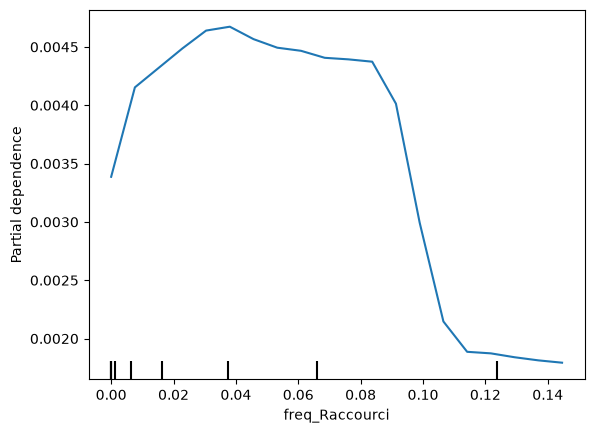

In [69]:
# Q5 : dépendance partielle (module sklearn.inspection)
from sklearn.inspection import PartialDependenceDisplay
PartialDependenceDisplay.from_estimator(rf, X_tr.sample(300, random_state=0), ["freq_Raccourci"],
                                        target=rf.classes_[0], grid_resolution=20)
plt.show()


**Réponses aux cinq questions**

1. **Confiance dans une prédiction :** `predict_proba` donne, pour chaque utilisateur, la moyenne des probabilités données par les 500 arbres (approximativement la part des arbres qui votent pour lui). Une valeur élevée signifie que les arbres sont d'accord ; une valeur faible signale une prédiction douteuse.
2. **Facteurs d'une prédiction particulière :** scikit-learn ne le fournit pas directement pour une forêt. On peut suivre le chemin d'une session dans les arbres avec `decision_path`, ou utiliser des bibliothèques externes (`treeinterpreter`, `SHAP`) qui décomposent une prédiction en contributions de chaque variable.
3. **Prédicteurs les plus forts :** `feature_importances_` mesure combien chaque variable aide les arbres à séparer les classes. (à compléter avec le top 10 obtenu)
4. **Variables redondantes :** deux variables très corrélées apportent la même information ; on pourrait en supprimer une sans perte de performance. (à compléter avec les paires obtenues)
5. **Effet d'une variable :** la dépendance partielle montre comment la probabilité d'un utilisateur évolue quand on fait varier une variable, toutes les autres restant égales. (à compléter avec la lecture du graphique)


## Evaluation sur l'ensemble de données de test

Il s'agit enfin d'utiliser votre modèle sur l'ensemble de données de test fourni.

In [ ]:
#TODO: preprocess test dataset, compute features values and post-process it (handle string, etc.)
test_processed_df = # TODO

In [ ]:
preds_test =  votre_modele.predict(test_processed_df)
preds_test

## Soumission à la compétition Kaggle

Il faut bien mettre en forme le fichier que vous pourrez utiliser pour soumettre sur le site de la compétitiokn.

In [ ]:
preds_test = pd.Categorical.from_codes(preds_test, features_train["util"].cat.categories)
df_subm = pd.DataFrame(preds_test)
df_subm = df_subm.rename_axis('RowId')
df_subm.rename(columns={0: 'prediction'}, inplace=True)
df_subm.index = df_subm.index + 1
df_subm

In [ ]:
df_subm.to_csv('submission.csv')